In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc

In [2]:
all_parameters = []
alle_arrays = []

with open("Grid_search_ellipses_6_all_Eigenvalues_nodal_line_detection_1_1_3/Results_from_files", "r", encoding="utf-8") as f:
    for zeile in f:
        teile = zeile.strip().split()
        liste = [float(teile[0]), float(teile[1]), float(teile[2])]

        if teile[3] == "True":
            liste.append(0)
        elif teile[3] == "False":
            liste.append(1)
        else:
            liste.append(-1)
        #parameters = np.array(liste)

        rest_array = np.array([complex(x) for x in teile[4:]])

        all_parameters.append(liste)
        alle_arrays.append(rest_array)

all_parameters_1 = np.array(all_parameters)


In [3]:
all_parameters = []
alle_arrays = []

with open("Grid_search_ellipses_6_all_Eigenvalues_nodal_line_detection_1_1_7/Results_from_files", "r", encoding="utf-8") as f:
    for zeile in f:
        teile = zeile.strip().split()
        liste = [float(teile[0]), float(teile[1]), float(teile[2])]

        if teile[3] == "True":
            liste.append(0)
        elif teile[3] == "False":
            liste.append(1)
        else:
            liste.append(-1)
        #parameters = np.array(liste)

        rest_array = np.array([complex(x) for x in teile[4:]])

        all_parameters.append(liste)
        alle_arrays.append(rest_array)

all_parameters_2 = np.array(all_parameters)


In [4]:
all_parameters = np.vstack((all_parameters_1, all_parameters_2))
all_parameters

array([[0.32, 0.2 , 0.05, 0.  ],
       [1.42, 0.01, 0.75, 0.  ],
       [1.42, 0.01, 0.65, 0.  ],
       ...,
       [1.04, 0.18, 0.47, 1.  ],
       [1.04, 0.18, 0.53, 1.  ],
       [1.04, 0.18, 0.39, 1.  ]], shape=(1890, 4))

In [5]:
all_parameters_before = np.copy(all_parameters)
all_parameters_before

array([[0.32, 0.2 , 0.05, 0.  ],
       [1.42, 0.01, 0.75, 0.  ],
       [1.42, 0.01, 0.65, 0.  ],
       ...,
       [1.04, 0.18, 0.47, 1.  ],
       [1.04, 0.18, 0.53, 1.  ],
       [1.04, 0.18, 0.39, 1.  ]], shape=(1890, 4))

In [6]:
all_parameters_before[all_parameters_before[:,0]==1.08]

array([[ 1.08,  0.01,  0.25,  0.  ],
       [ 1.08,  0.01,  0.35,  0.  ],
       [ 1.08,  0.01,  0.45,  0.  ],
       [ 1.08,  0.2 ,  0.25,  0.  ],
       [ 1.08,  0.2 ,  0.35,  1.  ],
       [ 1.08,  0.2 ,  0.55,  0.  ],
       [ 1.08,  0.2 ,  0.15,  0.  ],
       [ 1.08,  0.2 ,  0.45,  0.  ],
       [ 1.08,  0.2 ,  0.05,  0.  ],
       [ 1.08,  0.1 ,  0.25,  0.  ],
       [ 1.08,  0.1 ,  0.35,  0.  ],
       [ 1.08,  0.1 ,  0.55,  0.  ],
       [ 1.08,  0.1 ,  0.15,  0.  ],
       [ 1.08,  0.1 ,  0.45,  0.  ],
       [ 1.08,  0.3 ,  0.25,  0.  ],
       [ 1.08,  0.3 ,  0.35,  1.  ],
       [ 1.08,  0.3 ,  0.55, -1.  ],
       [ 1.08,  0.3 ,  0.15,  0.  ],
       [ 1.08,  0.3 ,  0.45,  1.  ],
       [ 1.08,  0.3 ,  0.05,  0.  ],
       [ 1.08,  0.8 ,  0.25,  0.  ],
       [ 1.08,  0.8 ,  0.35,  0.  ],
       [ 1.08,  0.8 ,  0.15,  0.  ],
       [ 1.08,  0.8 ,  0.05,  0.  ],
       [ 1.08,  0.4 ,  0.25,  0.  ],
       [ 1.08,  0.4 ,  0.35,  0.  ],
       [ 1.08,  0.4 ,  0.55, -1.  ],
 

In [7]:
Moore_6_1_12_1 = pd.read_csv("Moore_neighbor_6_1_2_1/Parameters_Eigenvalues.csv")
Moore_6_1_12_1

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.46,0.41,1.12,False,0,0j,False
1,[0.46],[0.39],1.12,False,0,0j,False
2,[0.46],[0.39],1.12,False,[4.67671223-4.45467356e-07j 4.67902028-4.61628...,(3.3424143820928713-1.159056103367164e-12j),True
3,[0.48],[0.39],1.12,False,0,0,False
4,[0.48],[0.39],1.12,False,[4.70481478-4.73999723e-07j 4.70642549-5.01238...,(3.4460876097356623-8.591578671107747e-13j),True
5,[0.48],[0.41],1.12,False,0,0,False
6,[0.48],[0.41],1.12,False,[4.8135164 -5.03973374e-07j 4.81511301-5.53391...,(3.4582217836287574-1.6415619946185864e-13j),True
7,[0.48],[0.43],1.12,False,0,0,False
8,[0.48],[0.43],1.12,False,[4.92475561-5.39079893e-07j 4.92634166-6.17588...,(3.4693117457404985+7.277470475864909e-14j),True
9,[0.46],[0.43],1.12,False,0,0,False


In [8]:
Moore_6_1_12 = []

In [9]:
Moore_6_1_12.append(Moore_6_1_12_1[:11:2])

In [10]:
Moore_6_1_12.append(Moore_6_1_12_1[13:34:2])

In [11]:
Moore_6_1_12_2 = pd.read_csv("Moore_neighbor_6_1_12_3/Parameters_Eigenvalues.csv")
Moore_6_1_12.append(Moore_6_1_12_2[::2])

In [12]:
Moore_6_1_12_3 = pd.read_csv("Moore_neighbor_6_1_12_4/Parameters_Eigenvalues.csv")
Moore_6_1_12.append(Moore_6_1_12_3[:9:2])

In [13]:
Moore_6_1_12.append(Moore_6_1_12_3[11:20:2])

In [14]:
Moore_6_1_12 = pd.concat(Moore_6_1_12, axis=0, ignore_index=True)
Moore_6_1_12

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.46,0.41,1.12,False,0,0j,False
1,[0.46],[0.39],1.12,False,[4.67671223-4.45467356e-07j 4.67902028-4.61628...,(3.3424143820928713-1.159056103367164e-12j),True
2,[0.48],[0.39],1.12,False,[4.70481478-4.73999723e-07j 4.70642549-5.01238...,(3.4460876097356623-8.591578671107747e-13j),True
3,[0.48],[0.41],1.12,False,[4.8135164 -5.03973374e-07j 4.81511301-5.53391...,(3.4582217836287574-1.6415619946185864e-13j),True
4,[0.48],[0.43],1.12,False,[4.92475561-5.39079893e-07j 4.92634166-6.17588...,(3.4693117457404985+7.277470475864909e-14j),True
5,[0.46],[0.43],1.12,False,[4.89087243-5.01388041e-07j 4.8932015 -5.56238...,(3.364949624378482-1.9716468115043267e-13j),False
6,[0.48],[0.45],1.12,False,[5.03845279-5.83143938e-07j 5.04003757-6.96861...,(3.4794507776437458-1.0170683631053545e-13j),False
7,[0.5],[0.43],1.12,False,[4.95651873-5.76315253e-07j 4.95756656-6.83646...,(3.580677556051861-1.3767715819197577e-13j),True
8,[0.5],[0.45],1.12,False,[5.07349495-6.3092592e-07j 5.07452973-4.399137...,(3.591136407240306-6.21401485479681e-14j),True
9,[0.5],[0.47],1.12,False,[5.19320537-7.07359516e-07j 5.19423473-8.54520...,(3.6007065197141177+6.332049479955433e-14j),False


In [15]:
Moore_6_1_04_1 = pd.read_csv("Moore_neighbor_6_1_2_2/Parameters_Eigenvalues.csv")
Moore_6_1_04 = []
Moore_6_1_04_1

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.24,0.43,1.04,False,0,0j,False
1,[0.26],[0.43],1.04,False,0,0j,False
2,[0.26],[0.43],1.04,False,[4.07646158-7.01183405e-08j 4.11674228-7.00663...,(2.8764799630034745-6.745038284300182e-13j),True
3,[0.26],[0.45],1.04,False,0,0,False
4,[0.26],[0.45],1.04,False,[4.12450491-6.84215432e-08j 4.16520405-6.85722...,(2.8837224585178136-1.6371325498781258e-13j),False
5,[0.28],[0.43],1.04,False,0,0,False
6,[0.28],[0.43],1.04,False,[4.1388748 -8.21475842e-08j 4.17617378-8.18684...,(2.949151986892484-4.21832830306844e-13j),True
7,[0.28],[0.45],1.04,False,0,0,False
8,[0.28],[0.45],1.04,False,[4.19016435-8.01838630e-08j 4.22797639-8.02111...,(2.9566831616132325-9.64471485612627e-14j),True
9,[0.28],[0.47],1.04,False,0,0,False


In [16]:
Moore_6_1_04.append(Moore_6_1_04_1[:15:2])

In [17]:
Moore_6_1_04.append(Moore_6_1_04_1[17:30:2])

In [18]:
Moore_6_1_04.append(Moore_6_1_04_1[32::2])

In [19]:
Moore_6_1_04

[         a       b  distance  Failed  \
 0     0.24    0.43      1.04   False   
 2   [0.26]  [0.43]      1.04   False   
 4   [0.26]  [0.45]      1.04   False   
 6   [0.28]  [0.43]      1.04   False   
 8   [0.28]  [0.45]      1.04   False   
 10  [0.28]  [0.47]      1.04   False   
 12   [0.3]  [0.45]      1.04   False   
 14   [0.3]  [0.47]      1.04   False   
 
                                            second_eig  \
 0                                                   0   
 2   [4.07646158-7.01183405e-08j 4.11674228-7.00663...   
 4   [4.12450491-6.84215432e-08j 4.16520405-6.85722...   
 6   [4.1388748 -8.21475842e-08j 4.17617378-8.18684...   
 8   [4.19016435-8.01838630e-08j 4.22797639-8.02111...   
 10  [4.23968231-7.79388172e-08j 4.27798616-7.82109...   
 12  [4.25570887-9.48609885e-08j 4.29040202-2.10035...   
 14  [4.30881207-9.23119389e-08j 4.34409727-8.86591...   
 
                                        first_eig  touches_boundary  
 0                                 

In [20]:
Moore_6_1_02_1 = pd.read_csv("Moore_neighbor_6_1_2_3/Parameters_Eigenvalues.csv")
Moore_6_1_02 = []
Moore_6_1_02.append(Moore_6_1_02_1[:7:2])

In [21]:
Moore_6_1_02.append(Moore_6_1_02_1[9::2])

In [22]:
Moore_6_1_06_1 = pd.read_csv("Moore_neighbor_6_1_2_4/Parameters_Eigenvalues.csv")
Moore_6_1_06 = []
Moore_6_1_06.append(Moore_6_1_06_1[::2])


In [23]:
Moore_6_1_08_1 = pd.read_csv("Moore_neighbor_6_1_2_5/Parameters_Eigenvalues.csv")
Moore_6_1_08 = []
Moore_6_1_08.append(Moore_6_1_08_1[:21:2])

In [24]:
Moore_6_1_08.append(Moore_6_1_08_1[23:26:2])

In [25]:
Moore_6_1_08.append(Moore_6_1_08_1[28:35:2])

In [26]:
Moore_6_1_08.append(Moore_6_1_08_1[37:46:2])

In [27]:
Moore_6_1_08.append(Moore_6_1_08_1[48:51:2])

In [28]:
Moore_6_1_08.append(Moore_6_1_08_1[53::2])

In [29]:
Moore_6_1_08 = pd.concat(Moore_6_1_08, axis=0, ignore_index=True)
Moore_6_1_08

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.38,0.43,1.08,False,0,0j,False
1,[0.4],[0.41],1.08,False,[4.49514603+2.21872722e-12j 4.49514603+1.03131...,(3.266173230749302-3.3752065050239735e-13j),True
2,[0.4],[0.43],1.08,False,[4.63873423-2.96753628e-07j 4.64966653-2.93903...,(3.276238719409147-6.954223039044575e-14j),True
3,[0.4],[0.45],1.08,False,[4.72492685-3.03995472e-07j 4.73622175-3.05259...,(3.2853932088355107-9.974706825782988e-15j),False
4,[0.42],[0.43],1.08,False,[4.68564984-3.34698588e-07j 4.69416468-3.34506...,(3.374129739187777-3.4507991347740715e-14j),True
5,[0.42],[0.45],1.08,False,[4.77583581-3.45480066e-07j 4.78460652-3.51238...,(3.383587494548694-4.599965199537333e-15j),True
6,[0.42],[0.47],1.08,False,[4.8664304 -3.55768667e-07j 4.87551621-3.68890...,(3.3922023074850287-4.1388954613468263e-16j),False
7,[0.44],[0.45],1.08,False,[4.82390859-3.87856896e-07j 4.83054754-4.01234...,(3.488195320938967-1.4382773419988113e-15j),True
8,[0.44],[0.47],1.08,False,[4.91874397-4.03018328e-07j 4.92559499-4.27037...,(3.4971009888014177-8.286066961154086e-16j),True
9,[0.44],[0.49],1.08,False,[5.01416152-4.19081159e-07j 5.02127654-4.54678...,(3.5052250224122243+1.942443437510801e-15j),True


In [30]:
Moore_6_1_02_2 = pd.read_csv("Moore_neighbor_6_1_2_6/Parameters_Eigenvalues.csv")
Moore_6_1_02.append(Moore_6_1_02_2[::2])
Moore_6_1_02 = pd.concat(Moore_6_1_02, axis=0, ignore_index=True)
Moore_6_1_02

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.22,0.51,1.02,False,0,0j,False
1,[0.24],[0.51],1.02,False,[4.08654212-4.93650405e-08j 4.13257491-4.97431...,(2.905811462005392-2.6848987654092533e-15j),True
2,[0.24],[0.53],1.02,False,[4.12003735-4.88470739e-08j 4.16599751-4.94885...,(2.9103054915163376-8.130155050146136e-15j),True
3,[0.22],[0.53],1.02,False,[4.0460127 -4.45709134e-08j 4.09375292-4.41384...,(2.840341807573887+2.45680029694284e-15j),False
4,[0.24],[0.55],1.02,True,0,0,True
5,[0.22],[0.55],1.02,True,0,0,True
6,0.16,0.53,1.02,False,0,0j,False
7,[0.16],[0.55],1.02,False,[3.85871153-3.71094603e-08j 3.91065149-3.74829...,(2.6546517184996237-3.0001968089920897e-15j),False
8,[0.18],[0.55],1.02,False,[3.92842 -3.91464494e-08j 3.97894505-3.95222...,(2.714538973369492-4.709618318600179e-15j),False
9,[0.18],[0.53],1.02,False,[3.90408277-3.85941517e-08j 3.95502229-3.85523...,(2.7112193907076105-3.779710380271716e-15j),False


In [31]:
Moore_6_1_04_2 = pd.read_csv("Moore_neighbor_6_1_2_7/Parameters_Eigenvalues.csv")
Moore_6_1_04.append(Moore_6_1_04_2[:21:2])

In [32]:
Moore_6_1_04.append(Moore_6_1_04_2[23:30:2])

In [33]:
Moore_6_1_04.append(Moore_6_1_04_2[32:49:2])

In [34]:
Moore_6_1_04.append(Moore_6_1_04_2[51:64:2])

In [35]:
Moore_6_1_04.append(Moore_6_1_04_2[66::2])

In [36]:
Moore_6_1_04_3 = pd.read_csv("Moore_neighbor_6_1_04_3/Parameters_Eigenvalues.csv")
Moore_6_1_04.append(Moore_6_1_04_3[::2])

In [37]:
Moore_6_1_04_4 = pd.read_csv("Moore_neighbor_6_1_04_5/Parameters_Eigenvalues.csv")
Moore_6_1_04.append(Moore_6_1_04_4[::2])

In [38]:
Moore_6_1_04_5 = pd.read_csv("Moore_neighbor_6_1_04_8/Parameters_Eigenvalues.csv")
Moore_6_1_04.append(Moore_6_1_04_5[:7:2])

In [39]:
Moore_6_1_04.append(Moore_6_1_04_5[9:18:2])

In [40]:
Moore_6_1_04.append(Moore_6_1_04_5[20::2])

In [41]:
Moore_6_1_04 = pd.concat(Moore_6_1_04, axis=0, ignore_index=True)

In [42]:
Moore_6_1_06_2 = pd.read_csv("Moore_neighbor_6_1_2_8/Parameters_Eigenvalues.csv")
Moore_6_1_06.append(Moore_6_1_06_2[::2])

In [43]:
Moore_6_1_06_3 = pd.read_csv("Moore_neighbor_6_1_06_4/Parameters_Eigenvalues.csv")
Moore_6_1_06.append(Moore_6_1_06_3[:17:2])

In [44]:
Moore_6_1_06.append(Moore_6_1_06_3[19::2])

In [45]:
Moore_6_1_06_4 = pd.read_csv("Moore_neighbor_6_1_06_6/Parameters_Eigenvalues.csv")
Moore_6_1_06.append(Moore_6_1_06_4[::2])

In [46]:
Moore_6_1_06_5 = pd.read_csv("Moore_neighbor_6_1_06_7/Parameters_Eigenvalues.csv")
Moore_6_1_06.append(Moore_6_1_06_5[:5:2])

In [47]:
Moore_6_1_06.append(Moore_6_1_06_5[7::2])

In [48]:
Moore_6_1_06 = pd.concat(Moore_6_1_06, axis=0, ignore_index=True)
Moore_6_1_06

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.24,0.51,1.06,False,0,0j,False
1,[0.26],[0.51],1.06,False,[4.35748539-7.23578948e-08j 4.396723 -7.30205...,(2.827039392911374+2.522896933475927e-15j),False
2,[0.26],[0.49],1.06,False,[4.31115478-7.50019381e-08j 4.3499594 -7.55645...,(2.821786212365251-1.1562449301742697e-14j),False
3,[0.24],[0.49],1.06,False,[4.23822321-6.43086027e-08j 4.27960391-6.48019...,(2.755814869757276-2.7567481100044317e-14j),False
4,0.34,0.51,1.06,False,0,0j,False
5,[0.36],[0.51],1.06,False,[4.74075823-1.83671785e-07j 4.76390174-1.86280...,(3.2191718843841888+1.4979922705533418e-15j),False
6,[0.36],[0.49],1.06,False,[4.67232176-1.87396010e-07j 4.69462567-1.88364...,(3.212698788924154-2.4279134483100933e-16j),False
7,[0.34],[0.49],1.06,False,[4.60226252-1.55399593e-07j 4.62817977-1.56082...,(3.1252893613641968-2.602156447697723e-15j),False
8,0.36,0.51,1.06,False,0,0j,False
9,[0.38],[0.51],1.06,False,[4.81375228-2.22180495e-07j 4.83326528-2.26651...,(3.3122345200997194-3.46105502553357e-16j),True


In [49]:
Moore_6_1_10_1 = pd.read_csv("Moore_neighbor_6_1_2_9/Parameters_Eigenvalues.csv")
Moore_6_1_10 = []
Moore_6_1_10.append(Moore_6_1_10_1[:35:2])

In [50]:
Moore_6_1_10.append(Moore_6_1_10_1[37::2])

In [51]:
Moore_6_1_10_2 = pd.read_csv("Moore_neighbor_6_1_10_4/Parameters_Eigenvalues.csv")
Moore_6_1_10.append(Moore_6_1_10_2[::2])

In [52]:
Moore_6_1_10_3 = pd.read_csv("Moore_neighbor_6_1_10_5/Parameters_Eigenvalues.csv")
Moore_6_1_10.append(Moore_6_1_10_3[:11:2])

In [53]:
Moore_6_1_10.append(Moore_6_1_10_3[13:16:2])

In [54]:
Moore_6_1_10.append(Moore_6_1_10_3[18::2])

In [55]:
Moore_6_1_10 = pd.concat(Moore_6_1_10, axis=0, ignore_index=True)
Moore_6_1_10

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.42,0.43,1.1,False,0,0j,False
1,[0.44],[0.43],1.1,False,[4.79369526-4.17404624e-07j 4.79841556-4.34379...,(3.3694814284858534-4.6039509478872925e-14j),True
2,[0.44],[0.45],1.1,False,[4.89403013-4.37807898e-07j 4.89885816-4.68553...,(3.3791315168489526-6.0893042101325955e-15j),False
3,[0.46],[0.43],1.1,False,[4.8325219 -4.55726152e-07j 4.83592614-4.85495...,(3.4738129413957726+2.044985421272164e-13j),True
4,[0.46],[0.45],1.1,False,[4.93651035-4.81690462e-07j 4.93996661-5.30456...,(3.483773150083328+2.0369795927660775e-13j),True
5,[0.46],[0.47],1.1,False,[5.04204099-5.12178711e-07j 5.04557516-5.82734...,(3.4928681326747353+3.867861370262863e-13j),False
6,[0.48],[0.45],1.1,False,[4.97644374-5.25632567e-07j 4.9788497 -6.75816...,(3.595436154920792-7.078041536925252e-14j),True
7,[0.48],[0.47],1.1,False,[5.08586381-5.65780394e-07j 5.08830334-7.15979...,(3.6048286113341255+2.5435662516198916e-12j),True
8,[0.48],[0.49],1.1,False,[5.19706402-6.17845321e-07j 5.19955679-7.44859...,(3.6134150697600824-1.7755614436556293e-14j),False
9,[0.5],[0.47],1.1,False,[5.12717456-6.22143487e-07j 5.12880754-7.57537...,(3.7245183528415735-2.427419561808185e-14j),True


In [56]:
Moore_6_1_14_1 = pd.read_csv("Moore_neighbor_6_1_2_10/Parameters_Eigenvalues.csv")
Moore_6_1_14 = []
Moore_6_1_14.append(Moore_6_1_14_1[:29:2])

In [57]:
Moore_6_1_14.append(Moore_6_1_14_1[31:38:2])

In [58]:
Moore_6_1_14.append(Moore_6_1_14_1[40::2])

In [59]:
Moore_6_1_14_2 = pd.read_csv("Moore_neighbor_6_1_14_4/Parameters_Eigenvalues.csv")
Moore_6_1_14.append(Moore_6_1_14_2[::2])

In [60]:
Moore_6_1_14_3 = pd.read_csv("Moore_neighbor_6_1_14_5/Parameters_Eigenvalues.csv")
Moore_6_1_14.append(Moore_6_1_14_3[:11:2])

In [61]:
Moore_6_1_14.append(Moore_6_1_14_3[13::2])

In [62]:
Moore_6_1_14 = pd.concat(Moore_6_1_14, axis=0, ignore_index=True)
Moore_6_1_14

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.48,0.41,1.14,False,0,0j,False
1,[0.48],[0.39],1.14,False,[4.67554691-2.02327044e-12j 4.74661618-5.06319...,(3.3376676569463917-1.4164987040691647e-12j),True
2,[0.5],[0.39],1.14,False,[4.77083419-5.32087292e-07j 4.77150405-5.97334...,(3.4413680520919927-8.999622652974847e-13j),True
3,[0.5],[0.41],1.14,False,[4.88738094-5.72964039e-07j 4.88804009-6.78367...,(3.453661968795326-1.5686315354574484e-13j),True
4,[0.5],[0.43],1.14,False,[5.00723041-6.26529229e-07j 5.00787374-7.82483...,(3.4649172481047508+5.537900921680741e-15j),False
5,[0.52],[0.41],1.14,False,[4.9123436 -6.02754767e-07j 4.91275625-7.38494...,(3.564702449096914-2.33695522613825e-13j),True
6,[0.52],[0.43],1.14,False,[5.03488032-6.66306543e-07j 5.03527615-8.63314...,(3.576301818857317+1.7277594955973886e-13j),True
7,[0.52],[0.45],1.14,False,[5.16103021-7.60746055e-07j 5.16141126-1.01708...,(3.5869285298943714+4.1108374937703813e-13j),False
8,[0.54],[0.43],1.14,False,[5.06083201-7.07711215e-07j 5.06106586-9.50584...,(3.6953815042352725+1.1616183569971575e-13j),True
9,[0.54],[0.45],1.14,False,[5.189897 -8.24624233e-07j 5.19011833-1.13151...,(3.706340197864285-1.0247533466568776e-13j),True


In [63]:
def parse(x):
    return float(str(x).strip("[]"))
arr_correct_order = np.empty((1,3))
solution_all = np.array((1,1))
all_parameters = np.empty((1,4))
folders = [Moore_6_1_02, Moore_6_1_04, Moore_6_1_06, Moore_6_1_08, Moore_6_1_10, Moore_6_1_12, Moore_6_1_14]#, "Moore_neighbor_5_1_02_2", "Moore_neighbor_5_1_04_1", "Moore_neighbor_5_1_04_2", "Moore_neighbor_5_1_04_3", "Moore_neighbor_5_1_04_4", "Moore_neighbor_5_1_06_1", "Moore_neighbor_5_1_06_2", "Moore_neighbor_5_1_06_3", "Moore_neighbor_5_1_06_4", "Moore_neighbor_5_1_06_5", "Moore_neighbor_5_1_06_6", "Moore_neighbor_5_1_08_1", "Moore_neighbor_5_1_08_2"]
for folder in folders:
    print(folder)
    #Moore_5_1_02_1 = pd.read_csv(f"{folder}/Parameters_Eigenvalues.csv")
    arr =  folder.iloc[:, :3].applymap(parse).to_numpy()
    arr_correct_order_temp = arr[:,[2,0,1]]
    #arr_correct_order = np.vstack((arr_correct_order, arr_correct_order_temp))
    #print(arr_correct_order)
    check_failed = folder['Failed'].to_numpy()
    check_touches_boundary = folder['touches_boundary'].to_numpy()
    solution = np.zeros(check_failed.shape)
    solution[check_failed] = -1
    solution[~check_failed & check_touches_boundary] = 0
    solution[~check_failed & ~check_touches_boundary] = 1
    all_parameters_temp = np.column_stack((arr_correct_order_temp, solution))
    print(all_parameters_temp)
    all_parameters = np.vstack((all_parameters, all_parameters_temp))

        a       b  distance  Failed  \
0    0.22    0.51      1.02   False   
1  [0.24]  [0.51]      1.02   False   
2  [0.24]  [0.53]      1.02   False   
3  [0.22]  [0.53]      1.02   False   
4  [0.24]  [0.55]      1.02    True   
5  [0.22]  [0.55]      1.02    True   
6    0.16    0.53      1.02   False   
7  [0.16]  [0.55]      1.02   False   
8  [0.18]  [0.55]      1.02   False   
9  [0.18]  [0.53]      1.02   False   

                                          second_eig  \
0                                                  0   
1  [4.08654212-4.93650405e-08j 4.13257491-4.97431...   
2  [4.12003735-4.88470739e-08j 4.16599751-4.94885...   
3  [4.0460127 -4.45709134e-08j 4.09375292-4.41384...   
4                                                  0   
5                                                  0   
6                                                  0   
7  [3.85871153-3.71094603e-08j 3.91065149-3.74829...   
8  [3.92842   -3.91464494e-08j 3.97894505-3.95222...   
9  [3.9040

/tmp/ipykernel_361992/1680782595.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  arr =  folder.iloc[:, :3].applymap(parse).to_numpy()
/tmp/ipykernel_361992/1680782595.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  arr =  folder.iloc[:, :3].applymap(parse).to_numpy()
/tmp/ipykernel_361992/1680782595.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  arr =  folder.iloc[:, :3].applymap(parse).to_numpy()
/tmp/ipykernel_361992/1680782595.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  arr =  folder.iloc[:, :3].applymap(parse).to_numpy()
/tmp/ipykernel_361992/1680782595.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  arr =  folder.iloc[:, :3].applymap(parse).to_numpy()
/tmp/ipykernel_361992/1680782595.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map in

In [64]:
all_parameters_moore = np.copy(all_parameters)
all_parameters_moore = all_parameters_moore.round(3)
all_parameters_moore

array([[ 0.  ,  0.  ,  0.  ,  0.  ],
       [ 1.02,  0.22,  0.51,  1.  ],
       [ 1.02,  0.24,  0.51,  0.  ],
       ...,
       [ 1.14,  0.5 ,  0.53, -1.  ],
       [ 1.14,  0.48,  0.53,  0.  ],
       [ 1.14,  0.48,  0.51,  0.  ]], shape=(261, 4))

In [65]:
all_parameters = np.vstack((all_parameters_before, all_parameters))

In [66]:
yes_mask = all_parameters[:, 3] == 1
no_mask = all_parameters[:, 3] == 0
no_third_mask = all_parameters[:, 3] == 0.6
maybe_mask = all_parameters[:, 3] == 0.8
wrong_mask = all_parameters[:, 3] == -2
failed_mask = all_parameters[:, 3] == -1

yes = all_parameters[yes_mask]
no = all_parameters[no_mask]
no_third = all_parameters[no_third_mask]
maybe = all_parameters[maybe_mask]
wrong = all_parameters[wrong_mask]
failed = all_parameters[failed_mask]

In [67]:
all_dist = np.unique(all_parameters[:,0])

In [68]:
def calculate_width_maximum_width_of_ellipses(n_ellipses,distance,length):
    alpha12 = np.pi/n_ellipses
    width = np.sqrt(distance*distance - length*length/(np.tan(alpha12)*np.tan(alpha12)))
    return width

In [69]:
n_ellipses = 6

In [70]:
def moore_neighbor_contour_tracing_algorithm(algorithm, start_point, start_direction,  step_size, a_big_ell,b_big_ell,distance_small_ell,n_ellipses,n,alpha):
    eps = 1e-6
    entered_points = start_point
    result_entered_points = np.array([1])
    if rank == 0:
        try:
            parameters = pd.read_csv("Parameters_Eigenvalues.csv")
            new_parameters = pd.DataFrame({'a' : [start_point[0,0]], 'b' : [start_point[1,0]], 'distance' : [distance_small_ell], 'Failed': [False], 'second_eig' : [0], 'first_eig': [0], 'touches_boundary': [False]})
            parameters = pd.concat([parameters, new_parameters], axis = 0)
            parameters.to_csv("Parameters_Eigenvalues.csv", index=False)
        except:
            parameters = pd.DataFrame({'a' : [start_point[0,0]], 'b' : [start_point[1,0]], 'distance' : [distance_small_ell], 'Failed': [False], 'second_eig' : [0], 'first_eig': [0], 'touches_boundary': [False]})
            parameters.to_csv('Parameters_Eigenvalues.csv', index = False)
    directions = step_size * np.array([[0, 1, 1, 1, 0, -1, -1, -1], [-1, -1, 0, 1, 1, 1, 0, -1]])
    point_true_temp = start_point
    idx_before = start_direction + 2
    finish = False
    while True:
        if rank == 0:
            print(f"point_true_temp is {point_true_temp}")
        found = False
        for i in range(8):
            #print(f"i is {i}")
            #print(f"idx_before is {idx_before}")
            idx = (idx_before + 6 + i) % 8
            if rank == 0:
                print(idx)
            direction = directions[:,idx:idx+1]
            #print(f"direction is {direction}")
            try_point_temp = point_true_temp + direction
            #print(f"try_point_temp is {try_point_temp}")
            points_in = np.abs(try_point_temp - entered_points) < np.array([[eps], [eps]])
            #print(f"np.abs(try_point_temp - entered_points) is {np.abs(try_point_temp - entered_points)}")

            #print(f"points_in is {points_in}")
            #print(f"points_in.all(axis=0).any() is {points_in.all(axis=0).any()}")
            whole_points_in = points_in.all(axis=0)
            if whole_points_in.any() == False:
                #print(f"Here")
                result_try_point_temp = algorithm(a_big_ell,b_big_ell,try_point_temp[0], try_point_temp[1],distance_small_ell,n_ellipses,n,alpha)
                entered_points = np.hstack((entered_points,try_point_temp))
                result_entered_points = np.hstack((result_entered_points,result_try_point_temp))
                if rank == 0:
                    print(f"entered_points is {entered_points}")
                    print(f"result_entered_points is {result_entered_points}")
                if result_try_point_temp == 1:
                    if np.abs(step_size - try_point_temp[0]) < eps:
                        finish = True
                    point_true_temp = try_point_temp
                    found = True
                    break
            else:
                if result_entered_points[whole_points_in] == 1:
                    if rank == 0:
                        try:
                            parameters = pd.read_csv("Parameters_Eigenvalues.csv")
                            new_parameters = pd.DataFrame({'a' : [try_point_temp[0,0]], 'b' : [try_point_temp[1,0]], 'distance' : [distance_small_ell], 'Failed': [False], 'second_eig' : [0], 'first_eig': [0], 'touches_boundary': [False]})
                            parameters = pd.concat([parameters, new_parameters], axis = 0)
                            parameters.to_csv("Parameters_Eigenvalues.csv", index=False)
                        except:
                            parameters = pd.DataFrame({'a' : [try_point_temp[0,0]], 'b' : [try_point_temp[1,0]], 'distance' : [distance_small_ell], 'Failed': [False], 'second_eig' : [0], 'first_eig': [0], 'touches_boundary': [False]})
                            parameters.to_csv('Parameters_Eigenvalues.csv', index = False)
                    finish = True
                    break
                else:
                    if rank == 0:
                        try:
                            parameters = pd.read_csv("Parameters_Eigenvalues.csv")
                            new_parameters = pd.DataFrame({'a' : [try_point_temp[0,0]], 'b' : [try_point_temp[1,0]], 'distance' : [distance_small_ell], 'Failed': [False], 'second_eig' : [0], 'first_eig': [0], 'touches_boundary': [True]})
                            parameters = pd.concat([parameters, new_parameters], axis = 0)
                            parameters.to_csv("Parameters_Eigenvalues.csv", index=False)
                        except:
                            parameters = pd.DataFrame({'a' : [try_point_temp[0,0]], 'b' : [try_point_temp[1,0]], 'distance' : [distance_small_ell], 'Failed': [False], 'second_eig' : [0], 'first_eig': [0], 'touches_boundary': [True]})
                            parameters.to_csv('Parameters_Eigenvalues.csv', index = False)

        #print(f"entered_points is {entered_points}")
        #print(f"result_entered_points is {result_entered_points}")        
        
        idx_before = idx
        if found == False:
            break
        if finish == True:
            break
    return entered_points, result_entered_points

In [71]:
def is_true_parameter_set(all_parameters,dist,a,b):
    parameter_set = all_parameters[(np.abs(all_parameters[:,0] - dist) < 0.0001)  & (np.abs(all_parameters[:,1] - a) < 0.0001) & (np.abs(all_parameters[:,2] - b) < 0.0001)]
    if parameter_set.shape[0] == 0:
        parameter_result = 0
    else:
        parameter_result = parameter_set[-1,3]
    print(parameter_set)
    print(parameter_result)
    return parameter_result

In [72]:
def moore_neighbor_contour_tracing_algorithm(algorithm, all_parameters, start_point, start_direction, step_size):
    eps = 1e-6
    entered_points = start_point[1:,:]
    result_entered_points = np.array([1])
    directions = step_size * np.array([[0, 1, 1, 1, 0, -1, -1, -1], [-1, -1, 0, 1, 1, 1, 0, -1]])
    point_true_temp = start_point[1:,:]
    idx_before = start_direction + 2
    finish = False
    while True:
        print(f"point_true_temp is {point_true_temp}")
        found = False
        for i in range(8):
            #print(f"i is {i}")
            #print(f"idx_before is {idx_before}")
            idx = (idx_before + 6 + i) % 8
            #print(idx)
            direction = directions[:,idx:idx+1]
            #print(f"direction is {direction}")
            try_point_temp = point_true_temp + direction
            #print(f"try_point_temp is {try_point_temp}")
            points_in = np.abs(try_point_temp - entered_points) < np.array([[eps], [eps]])
            #print(f"np.abs(try_point_temp - entered_points) is {np.abs(try_point_temp - entered_points)}")

            #print(f"points_in is {points_in}")
            #print(f"points_in.all(axis=0).any() is {points_in.all(axis=0).any()}")
            whole_points_in = points_in.all(axis=0)
            if whole_points_in.any() == False:
                #print(f"Here")
                result_try_point_temp = algorithm(all_parameters, start_point[0], try_point_temp[0], try_point_temp[1])
                entered_points = np.hstack((entered_points,try_point_temp))
                result_entered_points = np.hstack((result_entered_points,result_try_point_temp))
                #print(f"entered_points is {entered_points}")
                #print(f"result_entered_points is {result_entered_points}")
                if result_try_point_temp == 1:
                    if np.abs(step_size - try_point_temp[0]) < eps:
                        finish = True
                    point_true_temp = try_point_temp
                    found = True
                    break
            else:
                if result_entered_points[whole_points_in] == 1:
                    finish = True
                    break
        #print(f"entered_points is {entered_points}")
        #print(f"result_entered_points is {result_entered_points}")        
        
        idx_before = idx
        if found == False:
            break
        if finish == True:
            break
    return entered_points, result_entered_points

In [73]:
start_point = np.array([[1.02, 1.04, 1.06, 1.08, 1.10, 1.12, 1.14],[0.02, 0.02, 0.02, 0.32, 0.42, 0.46, 0.5],[0.35, 0.33, 0.41, 0.53, 0.53, 0.51, 0.51]])
start_direction = np.array([0, 0, 0, 5, 6, 6, 5])
step_size = 0.02

In [74]:
entered_points_list = []
result_entered_points_list = []
parameters_temp_yes_append_list = []
for i in range(start_point.shape[1]):
    entered_points, result_entered_points = moore_neighbor_contour_tracing_algorithm(is_true_parameter_set, all_parameters, start_point[:,i:i+1], start_direction[i], step_size)
    parameters_temp_yes_append = entered_points[:,result_entered_points==1]
    entered_points_list.append(entered_points)
    result_entered_points_list.append(result_entered_points)
    parameters_temp_yes_append_list.append(parameters_temp_yes_append)

point_true_temp is [[0.02]
 [0.35]]
[[1.02 0.02 0.33 0.  ]]
0.0
[[1.02 0.04 0.33 0.  ]]
0.0
[[1.02 0.04 0.35 1.  ]]
1.0
point_true_temp is [[0.04]
 [0.35]]
[[1.02 0.06 0.33 0.  ]]
0.0
[[1.02 0.06 0.35 0.  ]]
0.0
[[1.02 0.06 0.37 1.  ]]
1.0
point_true_temp is [[0.06]
 [0.37]]
[[1.02 0.08 0.35 0.  ]]
0.0
[[1.02 0.08 0.37 0.  ]]
0.0
[[1.02 0.08 0.39 1.  ]]
1.0
point_true_temp is [[0.08]
 [0.39]]
[[1.02 0.1  0.37 0.  ]]
0.0
[[1.02 0.1  0.39 0.  ]]
0.0
[[1.02 0.1  0.41 1.  ]]
1.0
point_true_temp is [[0.1 ]
 [0.41]]
[[1.02 0.12 0.39 0.  ]]
0.0
[[1.02 0.12 0.41 1.  ]]
1.0
point_true_temp is [[0.12]
 [0.41]]
[[1.02 0.14 0.39 0.  ]]
0.0
[[1.02 0.14 0.41 0.  ]]
0.0
[[1.02 0.14 0.43 1.  ]]
1.0
point_true_temp is [[0.14]
 [0.43]]
[[1.02 0.16 0.41 0.  ]]
0.0
[[1.02 0.16 0.43 0.  ]]
0.0
[[1.02 0.16 0.45 1.  ]]
1.0
point_true_temp is [[0.16]
 [0.45]]
[[1.02 0.18 0.43 0.  ]]
0.0
[[1.02 0.18 0.45 0.  ]]
0.0
[[1.02 0.18 0.47 1.  ]]
1.0
point_true_temp is [[0.18]
 [0.47]]
[[1.02 0.2  0.45 0.  ]
 [1.02 0.

In [75]:
def calculate_length_maximum_width_of_ellipses(n_ellipses,distance,width):
    alpha12 = np.pi/n_ellipses
    length = np.sqrt((distance*distance - width*width)*(np.tan(alpha12)*np.tan(alpha12)))-0.05
    return length

In [76]:
import os

1.02
1.04
1.06
1.08
1.1
1.12
1.14


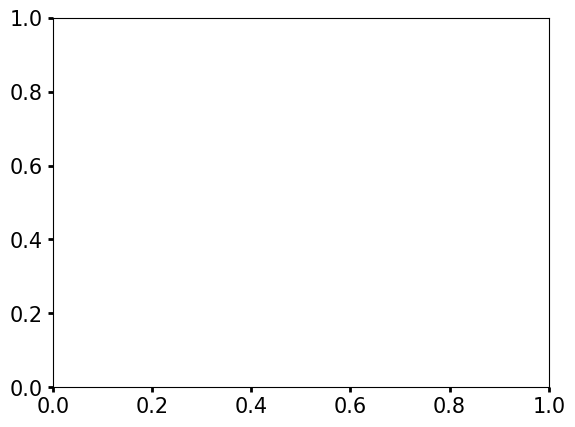

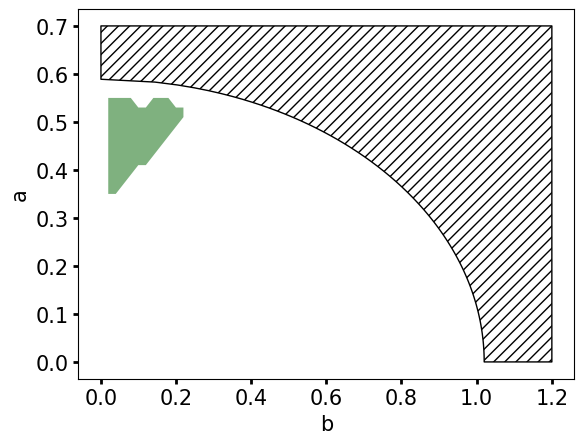

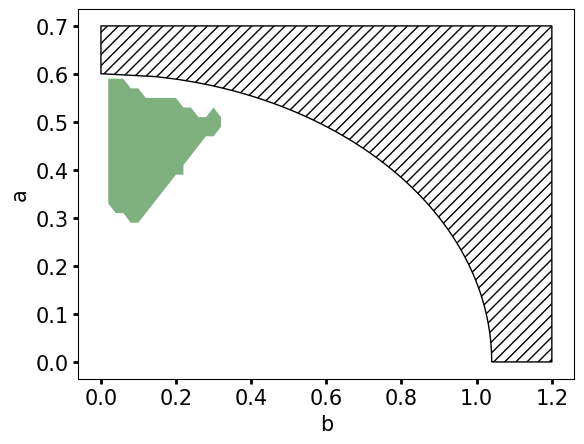

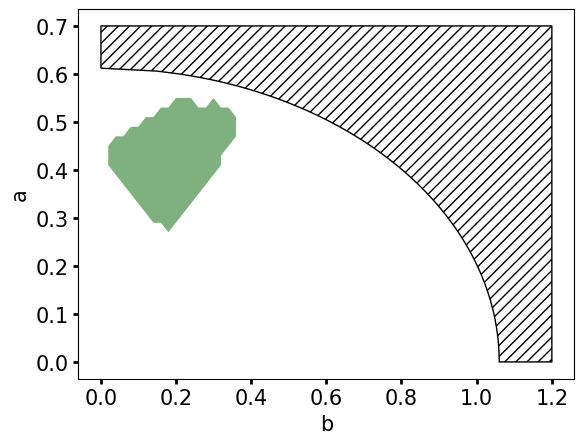

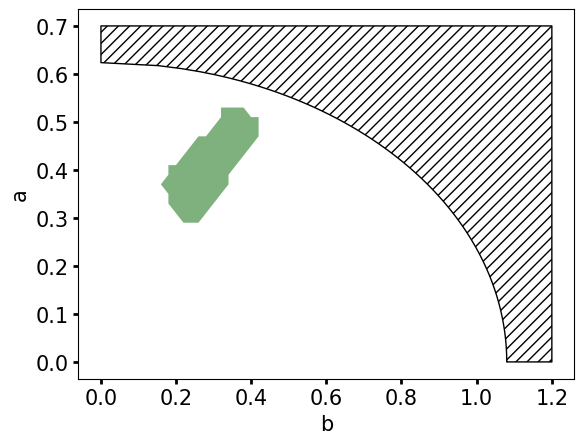

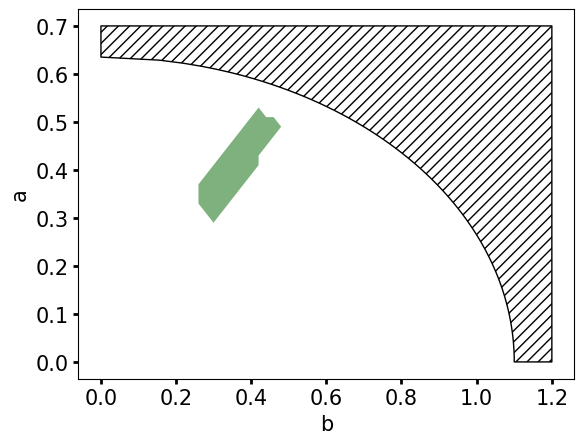

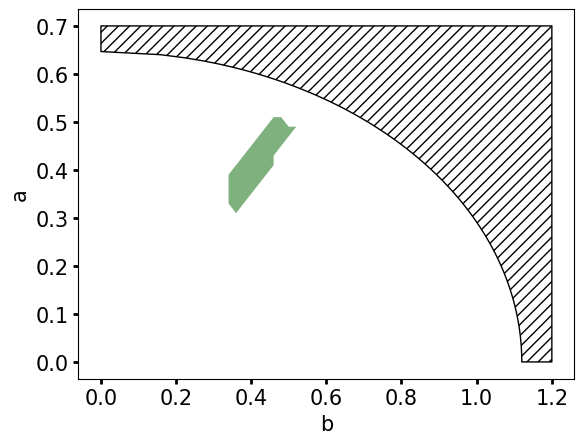

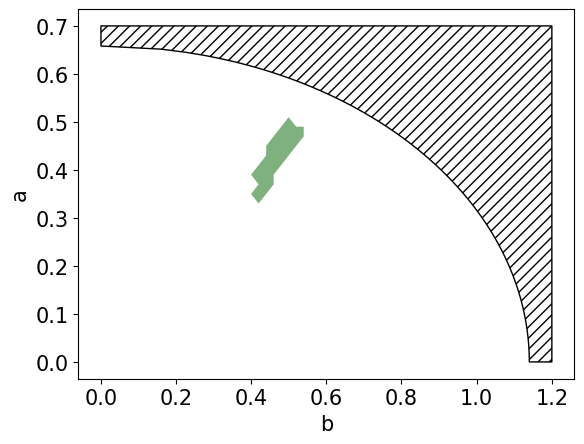

In [77]:
for i, dist in enumerate(all_dist[9:16]):
    dist_yes_mask = (yes[:,0] == dist)
    dist_maybe_mask = (maybe[:,0] == dist)
    dist_no_third_mask = (no_third[:,0] == dist)
    dist_no_mask = (no[:,0] == dist)
    dist_failed_mask = (failed[:,0] == dist)

    plt.rcParams.update({'font.size':15})
    plt.tick_params(axis='both', width=2)
    
    print(dist)
    fig = plt.figure()
    ax = fig.add_subplot(111)

    xlim_max = 1.2
    ylim_max = 0.7
 
    alpha12 = np.pi/n_ellipses
    max_length = dist * np.tan(alpha12)-0.0000001
    length_linspace = np.linspace(max_length,0,100, endpoint=True)
    length_full_plot = np.concatenate((length_linspace, np.zeros((100))))

    width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist, length_linspace)
    
    width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))

    plt.fill_between(width_full_plot, length_full_plot, ylim_max, facecolor='None',
    hatch='///',
    edgecolor='black',
    label='invalid / not tested')

    alpha12 = np.pi/(n_ellipses)
    num_max_length = np.sqrt((dist*dist - 0.05*0.05) * np.tan(alpha12)* np.tan(alpha12)) -0.05-0.0000001

    num_length_linspace = np.linspace(num_max_length,0.0,100, endpoint=True)
    num_length_full_plot = np.concatenate((num_length_linspace, np.zeros((100))))
    num_width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist, num_length_linspace+0.05)-0.05
    num_width_full_plot = np.concatenate((num_width_linspace, np.linspace(num_width_linspace[-1],width_linspace[-1], 100)))

    plt.fill(parameters_temp_yes_append_list[i][0,:], parameters_temp_yes_append_list[i][1,:], facecolor='darkgreen',
    alpha=0.5,
    label='valid region')

    ax.set_xlabel("b")
    ax.set_ylabel("a")

plt.show()

1.02
Plots_parametersets_6_ellipses/Parametersets_6_ellipses_distance_1_02.eps


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


1.04
Plots_parametersets_6_ellipses/Parametersets_6_ellipses_distance_1_04.eps
1.06
Plots_parametersets_6_ellipses/Parametersets_6_ellipses_distance_1_06.eps
1.08
Plots_parametersets_6_ellipses/Parametersets_6_ellipses_distance_1_08.eps


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


1.1
Plots_parametersets_6_ellipses/Parametersets_6_ellipses_distance_1_1.eps
1.12
Plots_parametersets_6_ellipses/Parametersets_6_ellipses_distance_1_12.eps
1.14
Plots_parametersets_6_ellipses/Parametersets_6_ellipses_distance_1_14.eps


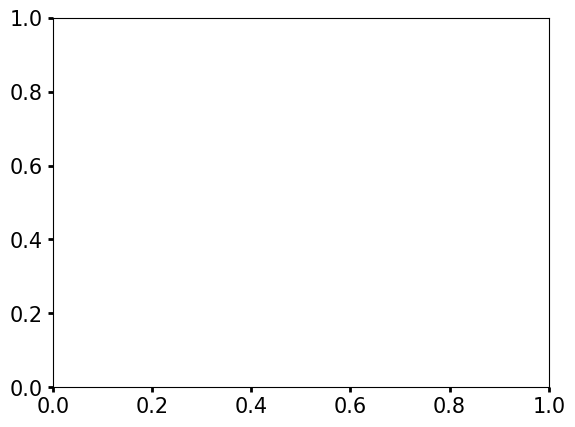

In [78]:
for i, dist in enumerate(all_dist[9:16]):
    dist_yes_mask = (yes[:,0] == dist)
    dist_maybe_mask = (maybe[:,0] == dist)
    dist_no_third_mask = (no_third[:,0] == dist)
    dist_no_mask = (no[:,0] == dist)
    dist_failed_mask = (failed[:,0] == dist)

    plt.rcParams.update({'font.size':15})
    plt.tick_params(axis='both', width=2)
    
    print(dist)
    fig = plt.figure()
    ax = fig.add_subplot(111)

    xlim_max = 1.2
    ylim_max = 0.7
 
    alpha12 = np.pi/n_ellipses
    max_length = dist * np.tan(alpha12)-0.0000001
    length_linspace = np.linspace(max_length,0,100, endpoint=True)
    length_full_plot = np.concatenate((length_linspace, np.zeros((100))))

    width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist, length_linspace)
    
    width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))

    plt.fill_between(width_full_plot, length_full_plot, ylim_max, facecolor='None',
    hatch='///',
    edgecolor='black',
    label='invalid / not tested')

    alpha12 = np.pi/(n_ellipses)
    num_max_length = np.sqrt((dist*dist - 0.05*0.05) * np.tan(alpha12)* np.tan(alpha12)) -0.05-0.0000001

    num_length_linspace = np.linspace(num_max_length,0.0,100, endpoint=True)
    num_length_full_plot = np.concatenate((num_length_linspace, np.zeros((100))))
    num_width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist, num_length_linspace+0.05)-0.05
    num_width_full_plot = np.concatenate((num_width_linspace, np.linspace(num_width_linspace[-1],width_linspace[-1], 100)))

    plt.fill(parameters_temp_yes_append_list[i][0,:], parameters_temp_yes_append_list[i][1,:], facecolor='darkgreen',
    alpha=0.5,
    label='valid region')

    ax.set_xlabel("b")
    ax.set_ylabel("a")
    os.makedirs("Plots_parametersets_6_ellipses", exist_ok = True)
    filename = f"Plots_parametersets_6_ellipses/Parametersets_6_ellipses_distance_{str(dist).replace('.', '_')}.eps"
    print(filename)
    plt.savefig(filename,dpi=300)
    plt.close()

plt.show()